# 21 — Final September Rolling Backtest
## Frozen NodeGRU-L14 vs LR13 benchmark

Notebook 21 is the **final held-out evaluation stage**.

The development experiments are already finished in Notebook 20. The model choice is therefore
**not re-selected from September results**.

### Frozen roles

- **Main model:** `NodeGRU-L14`
  - temporal sequence length = 14 days;
  - 13 local fire/current-history features;
  - three-seed ensemble using the seed-specific epoch counts fixed in Notebook 20.
- **Benchmark:** `LR13`
  - same 13 local fire/current-history features;
  - strong engineered temporal baseline.

### Why a rolling-origin backtest?

For each September forecast origin `t`:

```text
observations available through day t
        ↓
train only on forecast origins <= t-1
        ↓
use the 14-day sequence ending at t
        ↓
predict hotspot detection at t+1
```

Thus, when predicting `t+1`, the model may use information that would already be known by the end
of day `t`, but it never uses observations from `t+1` or later.

### Final-test discipline

- Architecture and feature set are frozen from development.
- Seed-specific epoch counts are read from NB20 development artifacts.
- September is **not used for model selection, threshold tuning, or hyperparameter tuning**.
- Thresholds are frozen from August development data before September evaluation.
- Primary metric remains **PR-AUC**.
- Raw neural scores are called **risk scores**, not literal probabilities unless calibrated.

This notebook produces:

1. final September overall metrics;
2. Emerging-3 and Persistent-context metrics;
3. daily rolling results;
4. actual-vs-predicted risk maps;
5. Emerging-event case studies;
6. final exported prediction table for thesis figures/tables.

In [2]:
# 1. Imports and final frozen configuration

from pathlib import Path
import sys
import json
import importlib
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    brier_score_loss,
    precision_recall_curve,
)

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 260)

# FROZEN FROM NB20 DEVELOPMENT DECISION
FINAL_MODEL_NAME = "NodeGRU-L14"
SEQ_LEN = 14
SEEDS = [42, 52, 62]

HIDDEN_DIM = 24
DROPOUT = 0.15
BATCH_SIZE = 8
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

DEV_END = pd.Timestamp("2026-08-31")
TEST_START = pd.Timestamp("2026-09-01")
TEST_END = pd.Timestamp("2026-09-09")

# Keep False unless intentionally rerunning the official final backtest.
# It is only a guard against accidental execution before reviewing the lock section.
FINAL_TEST_CONFIRMED = True

In [3]:
# 2. Resolve project root and required artifacts

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    candidate = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )
    if candidate.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the skripsi-karhut project root."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

NB20_EXPORT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_graph_temporal"
    / "t2"
    / "exports"
)

NB20_EPOCH_PATH = NB20_EXPORT_DIR / "epoch_diagnostics.csv"
NB20_PRED_PATH = NB20_EXPORT_DIR / "august_predictions.csv"
NB20_META_PATH = NB20_EXPORT_DIR / "nb20_methodology_metadata.json"

LOCK_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_dataset"
    / "exports"
    / "regional_domain_lock_train_only.json"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_final_test"
    / "t2"
)

EXPORT_DIR = RESULTS_DIR / "exports"
FIGURES_DIR = RESULTS_DIR / "figures"
MAPS_DIR = FIGURES_DIR / "daily_maps"

for p in [
    DATA_PATH,
    NB20_EPOCH_PATH,
    NB20_PRED_PATH,
    NB20_META_PATH,
    LOCK_PATH,
]:
    if not p.exists():
        raise FileNotFoundError(f"Required artifact missing: {p}")

for p in [RESULTS_DIR, EXPORT_DIR, FIGURES_DIR, MAPS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("NB20 exports :", NB20_EXPORT_DIR)
print("NB21 results :", RESULTS_DIR)

PROJECT_ROOT : c:\Users\Asus\Documents\skripsi-karhut
NB20 exports : c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_graph_temporal\t2\exports
NB21 results : c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2


In [4]:
# 3. Import reusable modules

SRC_ROOT = PROJECT_ROOT / "src"

if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

import karhut.evaluation as evaluation
import karhut.models as graph_models

importlib.reload(evaluation)
importlib.reload(graph_models)

import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch:", torch.__version__)
print("Device :", DEVICE)

if DEVICE == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cpu
Device : cpu


# PART A — Freeze the method **before** using September

The next cells read only NB20 development artifacts to reconstruct the frozen configuration.
No September performance is used to make these decisions.

In [5]:
# 4. Verify NB20 development evidence and freeze seed-specific epochs

nb20_meta = json.loads(
    NB20_META_PATH.read_text(encoding="utf-8")
)

epoch_diagnostics = pd.read_csv(
    NB20_EPOCH_PATH
)

nodegru_epochs = (
    epoch_diagnostics[
        epoch_diagnostics["Model"].eq(FINAL_MODEL_NAME)
    ][
        ["Seed", "Best internal epoch", "Internal tune PR-AUC"]
    ]
    .sort_values("Seed")
    .reset_index(drop=True)
)

assert nodegru_epochs["Seed"].tolist() == SEEDS

FROZEN_EPOCHS = {
    int(row["Seed"]): int(row["Best internal epoch"])
    for _, row in nodegru_epochs.iterrows()
}

# Expected from the executed NB20; assert to prevent silent drift.
EXPECTED_EPOCHS = {42: 18, 52: 22, 62: 21}
assert FROZEN_EPOCHS == EXPECTED_EPOCHS, (
    f"NB20 epoch lock differs from the reviewed run: {FROZEN_EPOCHS}"
)

print("FINAL MODEL        :", FINAL_MODEL_NAME)
print("SEQUENCE LENGTH    :", SEQ_LEN)
print("SEEDS              :", SEEDS)
print("FROZEN EPOCHS      :", FROZEN_EPOCHS)
print("NB20 September used:", nb20_meta.get("september_evaluated"))

display(nodegru_epochs)

FINAL MODEL        : NodeGRU-L14
SEQUENCE LENGTH    : 14
SEEDS              : [42, 52, 62]
FROZEN EPOCHS      : {42: 18, 52: 22, 62: 21}
NB20 September used: False


,Seed,Best internal epoch,Internal tune PR-AUC
0,42,18,0.539813
1,52,22,0.541995
2,62,21,0.536771


In [6]:
# 5. Exact frozen feature set

CURRENT_DAY_FIRE = [
    "fire_active",
    "fire_count",
    "frp_sum",
]

FIRE_HISTORY = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

FEATURES_13 = CURRENT_DAY_FIRE + FIRE_HISTORY
TARGET = "target_fire_active_t1"
CONTEXT = "active_days_prev3_incl_t"

assert len(FEATURES_13) == 13

print("Frozen features:", len(FEATURES_13))
display(pd.DataFrame({"feature": FEATURES_13}))

Frozen features: 13


,feature
0,fire_active
1,fire_count
2,frp_sum
3,fire_count_lag1
4,fire_count_lag3
5,fire_count_lag7
6,frp_sum_lag1
7,frp_sum_lag3
8,frp_sum_lag7
9,fire_count_roll3


In [7]:
# 6. Load data, but first construct the August development-only threshold lock

regional = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

regional["cell_id"] = regional["cell_id"].astype(str)

required = {
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    TARGET,
    CONTEXT,
    *FEATURES_13,
}

missing = sorted(required - set(regional.columns))
if missing:
    raise ValueError(f"Missing required columns: {missing}")

assert regional.duplicated(["date", "cell_id"]).sum() == 0

# Development-only frame. No September metrics are calculated here.
dev = regional[regional["date"] <= DEV_END].copy()

print("Development end:", dev["date"].max().date())
print("Development nodes:", dev["cell_id"].nunique())

Development end: 2026-08-31
Development nodes: 133


In [8]:
# 7. Freeze decision thresholds using August development data only


def best_f1_threshold(y_true, score):
    y = np.asarray(y_true).astype(int)
    s = np.asarray(score).astype(float)

    precision, recall, thresholds = precision_recall_curve(y, s)

    if len(thresholds) == 0:
        return 0.5

    f1 = (
        2 * precision[:-1] * recall[:-1]
        / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    )

    idx = int(np.nanargmax(f1))
    return float(thresholds[idx])


# LR13 August development prediction.
lr_dev_train = dev[dev["date"] <= pd.Timestamp("2026-07-31")].copy()
lr_dev_val = dev[dev["date"].between("2026-08-01", "2026-08-31")].copy()

lr_dev_model = evaluation.fit_logistic(
    lr_dev_train,
    FEATURES_13,
    TARGET,
    random_state=42,
)

lr_aug_score = lr_dev_model.predict_proba(
    lr_dev_val[FEATURES_13]
)[:, 1]

LR13_THRESHOLD = best_f1_threshold(
    lr_dev_val[TARGET],
    lr_aug_score,
)

# NodeGRU-L14: use only saved NB20 August predictions, averaged across seeds.
aug_pred = pd.read_csv(
    NB20_PRED_PATH,
    parse_dates=["date"],
)

aug_gru = (
    aug_pred[
        aug_pred["Model"].eq(FINAL_MODEL_NAME)
    ]
    .groupby(["date", "cell_id"], as_index=False)
    .agg(
        y_true=("y_true", "first"),
        score=("score", "mean"),
    )
)

assert not aug_gru.empty

GRU_THRESHOLD = best_f1_threshold(
    aug_gru["y_true"],
    aug_gru["score"],
)

FROZEN_THRESHOLDS = {
    "LR13": LR13_THRESHOLD,
    "NodeGRU-L14 ensemble": GRU_THRESHOLD,
}

print("Frozen August thresholds")
print("LR13             :", round(LR13_THRESHOLD, 6))
print("NodeGRU-L14 ens. :", round(GRU_THRESHOLD, 6))
print()
print("Primary final metric remains threshold-free PR-AUC.")

Frozen August thresholds
LR13             : 0.784092
NodeGRU-L14 ens. : 0.823995

Primary final metric remains threshold-free PR-AUC.


In [9]:
# 8. Write the final method lock BEFORE the September scoring loop

method_lock = {
    "region": "T2",
    "grid": "0.25 degree retained land nodes",
    "main_model": FINAL_MODEL_NAME,
    "benchmark": "LR13",
    "features": FEATURES_13,
    "sequence_length": SEQ_LEN,
    "seeds": SEEDS,
    "seed_specific_epochs": FROZEN_EPOCHS,
    "hidden_dim": HIDDEN_DIM,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "thresholds_frozen_from_august": FROZEN_THRESHOLDS,
    "test_start_origin": str(TEST_START.date()),
    "test_end_origin": str(TEST_END.date()),
    "evaluation": "rolling-origin end-of-day t -> target t+1",
    "primary_metric": "PR-AUC",
    "selection_uses_september": False,
    "raw_score_interpretation": "risk score, not calibrated probability",
}

FINAL_LOCK_PATH = EXPORT_DIR / "final_method_lock_before_test.json"
FINAL_LOCK_PATH.write_text(
    json.dumps(method_lock, indent=2),
    encoding="utf-8",
)

print("FINAL METHOD LOCK WRITTEN:")
print(FINAL_LOCK_PATH)
print()
print(json.dumps(method_lock, indent=2))

FINAL METHOD LOCK WRITTEN:
c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\exports\final_method_lock_before_test.json

{
  "region": "T2",
  "grid": "0.25 degree retained land nodes",
  "main_model": "NodeGRU-L14",
  "benchmark": "LR13",
  "features": [
    "fire_active",
    "fire_count",
    "frp_sum",
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7"
  ],
  "sequence_length": 14,
  "seeds": [
    42,
    52,
    62
  ],
  "seed_specific_epochs": {
    "42": 18,
    "52": 22,
    "62": 21
  },
  "hidden_dim": 24,
  "dropout": 0.15,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "thresholds_frozen_from_august": {
    "LR13": 0.7840915140395898,
    "NodeGRU-L14 ensemble": 0.8239948948224386
  },
  "test_start_origin": "2026-09-01",
  "test_end_origin": "2026-09-09",
  "evaluation":

# PART B — Open the final September rolling test

From this point onward, September outcomes are used **only for final evaluation**.
Do not return to model selection after viewing these results.

In [10]:
# 9. Final-test guard and date audit

if not FINAL_TEST_CONFIRMED:
    raise RuntimeError(
        "Set FINAL_TEST_CONFIRMED=True only when ready to run the official final test."
    )

node_table = (
    dev[["cell_id", "grid_lat", "grid_lon"]]
    .drop_duplicates("cell_id")
    .sort_values("cell_id")
    .reset_index(drop=True)
)

node_ids = node_table["cell_id"].astype(str).tolist()
N_NODES = len(node_ids)

assert N_NODES == 133

available_test_origins = sorted(
    regional.loc[
        regional["date"].between(TEST_START, TEST_END),
        "date",
    ].unique()
)

available_test_origins = [pd.Timestamp(x) for x in available_test_origins]

print("Nodes:", N_NODES)
print("Final forecast origins:")
for d in available_test_origins:
    print(" ", d.date(), "->", (d + pd.Timedelta(days=1)).date())

assert len(available_test_origins) == 9, (
    f"Expected 9 September forecast origins, found {len(available_test_origins)}"
)

Nodes: 133
Final forecast origins:
  2026-09-01 -> 2026-09-02
  2026-09-02 -> 2026-09-03
  2026-09-03 -> 2026-09-04
  2026-09-04 -> 2026-09-05
  2026-09-05 -> 2026-09-06
  2026-09-06 -> 2026-09-07
  2026-09-07 -> 2026-09-08
  2026-09-08 -> 2026-09-09
  2026-09-09 -> 2026-09-10


In [11]:
# 10. Dense daily arrays for temporal model

# Use all available predictor dates because September sequences need August context.
daily = graph_models.panel_to_daily_arrays(
    regional,
    FEATURES_13,
    TARGET,
    CONTEXT,
    node_ids,
)

DATES = pd.to_datetime(daily["dates"])
X_RAW = daily["X"]
Y = daily["y"]
C = daily["context"]

print("Dense X:", X_RAW.shape)
print("Dense y:", Y.shape)
print("Date range:", DATES.min().date(), "->", DATES.max().date())

Dense X: (125, 133, 13)
Dense y: (125, 133)
Date range: 2026-05-08 -> 2026-09-09


In [12]:
# 11. Final metric helpers


def metric_bundle(y_true, score, threshold):
    y = np.asarray(y_true).reshape(-1).astype(int)
    s = np.asarray(score).reshape(-1).astype(float)
    pred = (s >= threshold).astype(int)

    return {
        "Rows": int(len(y)),
        "Positives": int(y.sum()),
        "Prevalence": float(y.mean()),
        "PR-AUC": float(average_precision_score(y, s)),
        "ROC-AUC": (
            float(roc_auc_score(y, s))
            if len(np.unique(y)) > 1
            else np.nan
        ),
        "Precision": float(precision_score(y, pred, zero_division=0)),
        "Recall": float(recall_score(y, pred, zero_division=0)),
        "F1": float(f1_score(y, pred, zero_division=0)),
        "Accuracy": float(accuracy_score(y, pred)),
        "Brier": float(brier_score_loss(y, s)),
        "Threshold": float(threshold),
    }


def safe_subset_metrics(frame, score_col, mask, threshold):
    sub = frame.loc[mask].copy()

    if len(sub) == 0:
        return {
            "Rows": 0,
            "Positives": 0,
            "Prevalence": np.nan,
            "PR-AUC": np.nan,
            "ROC-AUC": np.nan,
            "Precision": np.nan,
            "Recall": np.nan,
            "F1": np.nan,
            "Accuracy": np.nan,
            "Brier": np.nan,
            "Threshold": threshold,
        }

    return metric_bundle(
        sub["y_true"],
        sub[score_col],
        threshold,
    )

## Rolling-origin rule used below

At forecast origin `t`:

- training predictor rows end at `t-1`;
- therefore the latest training target is day `t`, which is already observed by the end of day `t`;
- the prediction uses features/sequence ending at day `t`;
- evaluation target is day `t+1`.

No observation from `t+1` is used during fitting.

In [13]:
# 12. Official rolling September backtest

rolling_rows = []
runtime_rows = []

for origin in available_test_origins:

    forecast_date = origin + pd.Timedelta(days=1)
    train_origin_end = origin - pd.Timedelta(days=1)

    print()
    print("=" * 90)
    print(
        "Forecast origin:", origin.date(),
        "| target:", forecast_date.date(),
        "| train origins through:", train_origin_end.date(),
    )
    print("=" * 90)

    # ---------------------------------------------------------
    # LR13 rolling benchmark
    # ---------------------------------------------------------
    lr_train = regional[
        regional["date"] <= train_origin_end
    ].copy()

    lr_current = (
        regional[
            regional["date"].eq(origin)
        ]
        .set_index("cell_id")
        .reindex(node_ids)
        .reset_index()
    )

    assert len(lr_current) == N_NODES

    lr_model = evaluation.fit_logistic(
        lr_train,
        FEATURES_13,
        TARGET,
        random_state=42,
    )

    lr_score = lr_model.predict_proba(
        lr_current[FEATURES_13]
    )[:, 1]

    # ---------------------------------------------------------
    # NodeGRU-L14 rolling ensemble
    # ---------------------------------------------------------
    train_date_mask = DATES <= train_origin_end

    mean, std = graph_models.fit_standardizer(
        X_RAW,
        train_date_mask,
    )

    X_SCALED = graph_models.apply_standardizer(
        X_RAW,
        mean,
        std,
    )

    seq = graph_models.make_sequences(
        daily["dates"],
        X_SCALED,
        Y,
        C,
        seq_len=SEQ_LEN,
    )

    seq_dates = pd.to_datetime(seq["dates"])

    train_mask = seq_dates <= train_origin_end
    pred_mask = seq_dates == origin

    assert pred_mask.sum() == 1

    X_train = seq["X"][train_mask]
    y_train = seq["y"][train_mask]
    X_pred = seq["X"][pred_mask]

    seed_scores = []
    seed_seconds = []

    for seed in SEEDS:
        graph_models.set_seed(seed)

        model = graph_models.make_model(
            "nodegru",
            len(FEATURES_13),
            hidden_dim=HIDDEN_DIM,
            dropout=DROPOUT,
        )

        model, fit_seconds = graph_models.fit_fixed_epochs(
            model,
            X_train,
            y_train,
            seed=seed,
            epochs=FROZEN_EPOCHS[seed],
            device=DEVICE,
            batch_size=BATCH_SIZE,
            lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY,
        )

        score = graph_models.predict_proba(
            model,
            X_pred,
            device=DEVICE,
            batch_size=BATCH_SIZE,
        )[0]

        seed_scores.append(score)
        seed_seconds.append(fit_seconds)

    gru_score = np.mean(
        np.stack(seed_scores, axis=0),
        axis=0,
    )

    # Exact target/context aligned to current origin.
    current_daily_idx = np.where(DATES == origin)[0]
    assert len(current_daily_idx) == 1
    current_daily_idx = int(current_daily_idx[0])

    y_true = Y[current_daily_idx].astype(int)
    context = C[current_daily_idx]

    # Node coordinates in identical node order.
    coord = node_table.set_index("cell_id").reindex(node_ids)

    for i, node_id in enumerate(node_ids):
        rolling_rows.append({
            "origin_date": origin,
            "forecast_date": forecast_date,
            "cell_id": node_id,
            "grid_lat": float(coord.iloc[i]["grid_lat"]),
            "grid_lon": float(coord.iloc[i]["grid_lon"]),
            "y_true": int(y_true[i]),
            "active_days_prev3_incl_t": float(context[i]),
            "is_emerging_eligible": bool(context[i] == 0),
            "is_emerging_positive": bool((context[i] == 0) and (y_true[i] == 1)),
            "lr13_score": float(lr_score[i]),
            "nodegru_l14_score": float(gru_score[i]),
            "lr13_flag": bool(lr_score[i] >= LR13_THRESHOLD),
            "nodegru_l14_flag": bool(gru_score[i] >= GRU_THRESHOLD),
        })

    runtime_rows.append({
        "origin_date": origin,
        "forecast_date": forecast_date,
        "NodeGRU ensemble fit seconds": float(sum(seed_seconds)),
        "Mean per-seed seconds": float(np.mean(seed_seconds)),
    })

    print(
        "positives =", int(y_true.sum()),
        "| emerging positives =", int(((context == 0) & (y_true == 1)).sum()),
        "| GRU fit seconds =", round(float(sum(seed_seconds)), 2),
    )

final_predictions = pd.DataFrame(rolling_rows)
runtime_final = pd.DataFrame(runtime_rows)

print()
print("✅ OFFICIAL SEPTEMBER ROLLING BACKTEST COMPLETE")
print("Rows:", len(final_predictions))
print("Forecast dates:", final_predictions["forecast_date"].min().date(), "->", final_predictions["forecast_date"].max().date())


Forecast origin: 2026-09-01 | target: 2026-09-02 | train origins through: 2026-08-31
positives = 84 | emerging positives = 5 | GRU fit seconds = 29.08

Forecast origin: 2026-09-02 | target: 2026-09-03 | train origins through: 2026-09-01
positives = 91 | emerging positives = 1 | GRU fit seconds = 28.76

Forecast origin: 2026-09-03 | target: 2026-09-04 | train origins through: 2026-09-02
positives = 84 | emerging positives = 1 | GRU fit seconds = 29.4

Forecast origin: 2026-09-04 | target: 2026-09-05 | train origins through: 2026-09-03
positives = 81 | emerging positives = 2 | GRU fit seconds = 29.63

Forecast origin: 2026-09-05 | target: 2026-09-06 | train origins through: 2026-09-04
positives = 91 | emerging positives = 7 | GRU fit seconds = 29.95

Forecast origin: 2026-09-06 | target: 2026-09-07 | train origins through: 2026-09-05
positives = 52 | emerging positives = 0 | GRU fit seconds = 29.86

Forecast origin: 2026-09-07 | target: 2026-09-08 | train origins through: 2026-09-06
pos

# PART C — Final held-out metrics

After this point, the September results may be described and visualized, but they must **not** be
used to change the architecture/hyperparameters and rerun the test as if it were still unseen.

In [14]:
# 13. Overall final-test metrics

final_overall_rows = []

for model_name, score_col, threshold in [
    ("LR13", "lr13_score", LR13_THRESHOLD),
    ("NodeGRU-L14 ensemble", "nodegru_l14_score", GRU_THRESHOLD),
]:
    final_overall_rows.append({
        "Model": model_name,
        **metric_bundle(
            final_predictions["y_true"],
            final_predictions[score_col],
            threshold,
        ),
    })

final_overall = pd.DataFrame(final_overall_rows)

display(final_overall)

,Model,Rows,Positives,Prevalence,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier,Threshold
0,LR13,1197,684,0.571429,0.888116,0.863457,0.788904,0.852339,0.819396,0.785297,0.187359,0.784092
1,NodeGRU-L14 ensemble,1197,684,0.571429,0.882435,0.865785,0.764563,0.921053,0.835544,0.792815,0.213023,0.823995


In [15]:
# 14. Emerging-3 and Persistent-context final metrics

subgroup_rows = []

emerging_mask = final_predictions["is_emerging_eligible"]
persistent_mask = ~final_predictions["is_emerging_eligible"]

for model_name, score_col, threshold in [
    ("LR13", "lr13_score", LR13_THRESHOLD),
    ("NodeGRU-L14 ensemble", "nodegru_l14_score", GRU_THRESHOLD),
]:
    subgroup_rows.append({
        "Model": model_name,
        "Context": "Emerging-3 eligible",
        **safe_subset_metrics(
            final_predictions,
            score_col,
            emerging_mask,
            threshold,
        ),
    })

    subgroup_rows.append({
        "Model": model_name,
        "Context": "Persistent-context",
        **safe_subset_metrics(
            final_predictions,
            score_col,
            persistent_mask,
            threshold,
        ),
    })

final_subgroups = pd.DataFrame(subgroup_rows)

display(final_subgroups)

,Model,Context,Rows,Positives,Prevalence,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier,Threshold
0,LR13,Emerging-3 eligible,252,28,0.111111,0.289877,0.709104,1.000000,0.071429,0.133333,0.896825,0.111191,0.784092
1,LR13,Persistent-context,945,656,0.694180,0.897755,0.798609,0.788331,0.885671,0.834171,0.755556,0.207670,0.784092
2,NodeGRU-L14 ensemble,Emerging-3 eligible,252,28,0.111111,0.326900,0.742506,0.750000,0.107143,0.187500,0.896825,0.169909,0.823995
3,NodeGRU-L14 ensemble,Persistent-context,945,656,0.694180,0.891270,0.800337,0.764634,0.955793,0.849593,0.765079,0.224520,0.823995


In [16]:
# 15. Final deltas: main model minus LR13

lookup_overall = final_overall.set_index("Model")
lookup_sub = final_subgroups.pivot(
    index="Model",
    columns="Context",
    values="PR-AUC",
)

final_deltas = pd.DataFrame([
    {
        "Comparison": "NodeGRU-L14 - LR13",
        "Delta overall PR-AUC": (
            lookup_overall.loc["NodeGRU-L14 ensemble", "PR-AUC"]
            - lookup_overall.loc["LR13", "PR-AUC"]
        ),
        "Delta Emerging PR-AUC": (
            lookup_sub.loc["NodeGRU-L14 ensemble", "Emerging-3 eligible"]
            - lookup_sub.loc["LR13", "Emerging-3 eligible"]
        ),
        "Delta Persistent PR-AUC": (
            lookup_sub.loc["NodeGRU-L14 ensemble", "Persistent-context"]
            - lookup_sub.loc["LR13", "Persistent-context"]
        ),
    }
])

display(final_deltas)

,Comparison,Delta overall PR-AUC,Delta Emerging PR-AUC,Delta Persistent PR-AUC
0,NodeGRU-L14 - LR13,-0.005681,0.037022,-0.006485


In [17]:
# 16. Daily rolling metrics

daily_rows = []

for forecast_date, day in final_predictions.groupby("forecast_date"):
    for model_name, score_col, threshold in [
        ("LR13", "lr13_score", LR13_THRESHOLD),
        ("NodeGRU-L14 ensemble", "nodegru_l14_score", GRU_THRESHOLD),
    ]:
        m = metric_bundle(
            day["y_true"],
            day[score_col],
            threshold,
        )
        daily_rows.append({
            "forecast_date": forecast_date,
            "Model": model_name,
            **m,
        })

daily_metrics = pd.DataFrame(daily_rows)

display(
    daily_metrics[
        [
            "forecast_date",
            "Model",
            "Positives",
            "Prevalence",
            "PR-AUC",
            "Precision",
            "Recall",
            "F1",
        ]
    ]
)

,forecast_date,Model,Positives,Prevalence,PR-AUC,Precision,Recall,F1
0,2026-09-02,LR13,84,0.631579,0.946325,0.808511,0.904762,0.853933
1,2026-09-02,NodeGRU-L14 ensemble,84,0.631579,0.945209,0.822917,0.940476,0.877778
2,2026-09-03,LR13,91,0.684211,0.963455,0.919540,0.879121,0.898876
3,2026-09-03,NodeGRU-L14 ensemble,91,0.684211,0.959028,0.875000,0.923077,0.898396
4,2026-09-04,LR13,84,0.631579,0.958127,0.857143,0.928571,0.891429
5,2026-09-04,NodeGRU-L14 ensemble,84,0.631579,0.955441,0.821053,0.928571,0.871508
6,2026-09-05,LR13,81,0.609023,0.885124,0.818182,0.888889,0.852071
7,2026-09-05,NodeGRU-L14 ensemble,81,0.609023,0.901853,0.797872,0.925926,0.857143
8,2026-09-06,LR13,91,0.684211,0.941316,0.875000,0.846154,0.860335
9,2026-09-06,NodeGRU-L14 ensemble,91,0.684211,0.944720,0.872340,0.901099,0.886486


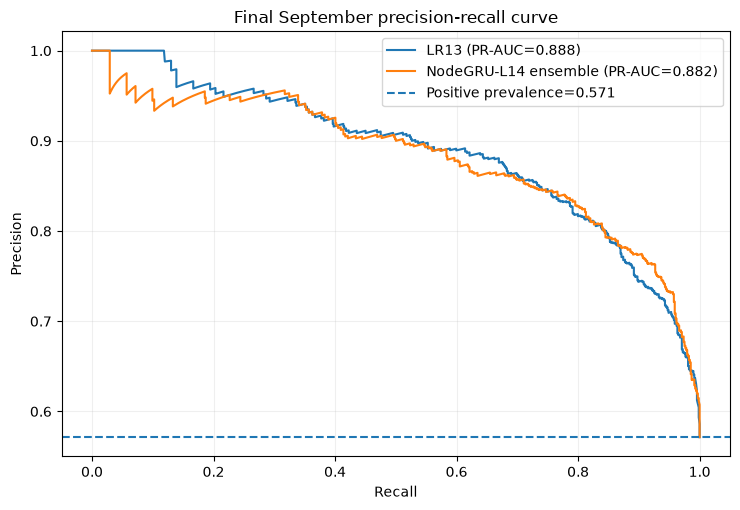

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\figures\01_final_precision_recall.png


In [18]:
# 17. Precision-Recall curve on the final test

fig, ax = plt.subplots(figsize=(7.5, 5.2))

for model_name, score_col in [
    ("LR13", "lr13_score"),
    ("NodeGRU-L14 ensemble", "nodegru_l14_score"),
]:
    p, r, _ = precision_recall_curve(
        final_predictions["y_true"],
        final_predictions[score_col],
    )

    pr = average_precision_score(
        final_predictions["y_true"],
        final_predictions[score_col],
    )

    ax.plot(
        r,
        p,
        label=f"{model_name} (PR-AUC={pr:.3f})",
    )

prevalence = final_predictions["y_true"].mean()
ax.axhline(
    prevalence,
    linestyle="--",
    label=f"Positive prevalence={prevalence:.3f}",
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Final September precision-recall curve")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

pr_fig = FIGURES_DIR / "01_final_precision_recall.png"
plt.savefig(pr_fig, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", pr_fig)

# PART D — Actual vs predicted maps

The map uses the **NodeGRU-L14 ensemble risk score** for each retained 0.25° land grid-cell.

- square color = risk score produced at forecast origin `t`;
- `×` marker = actual FIRMS-positive target at `t+1`;
- scores are **not interpreted as calibrated probabilities**.

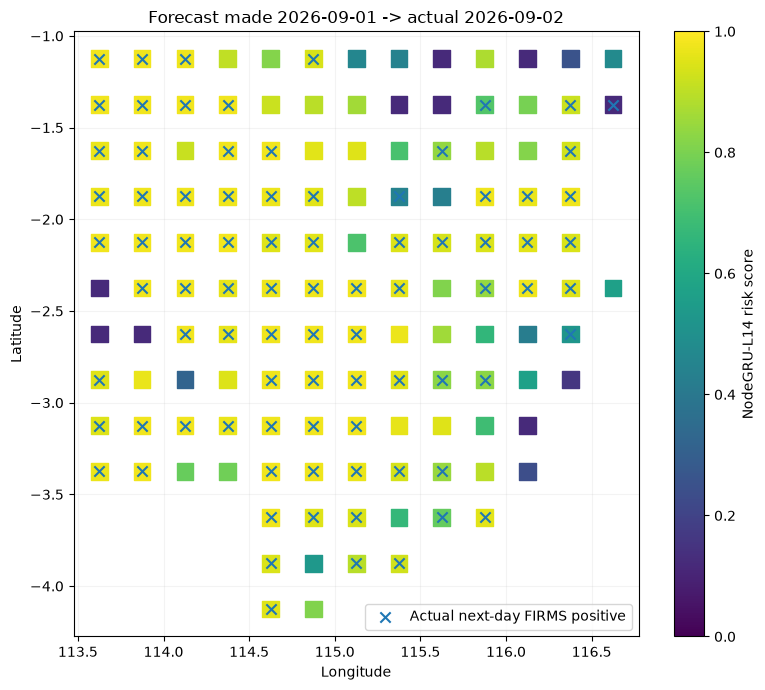

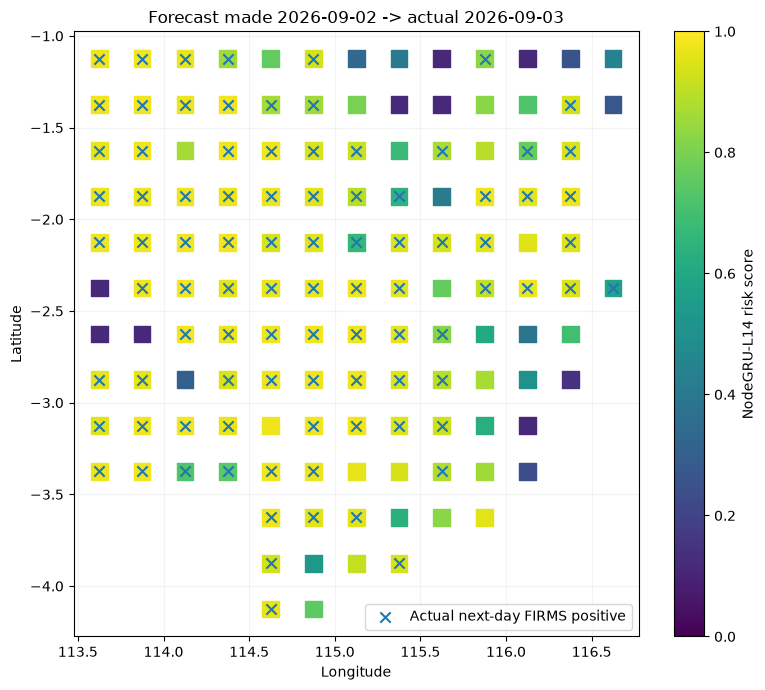

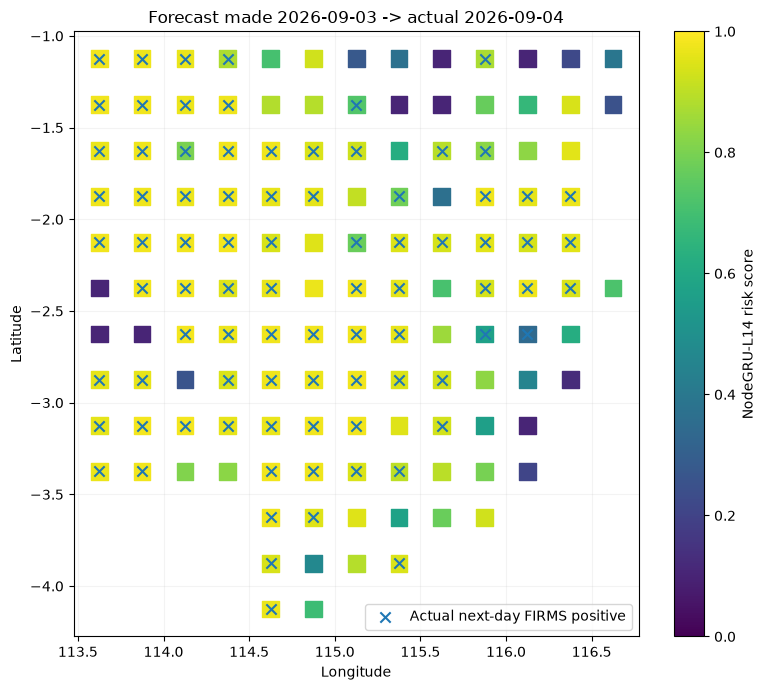

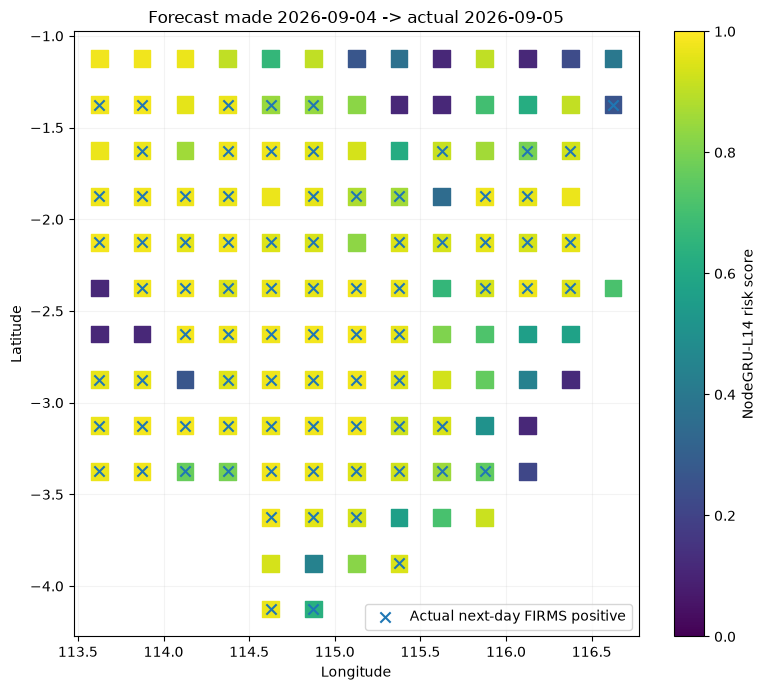

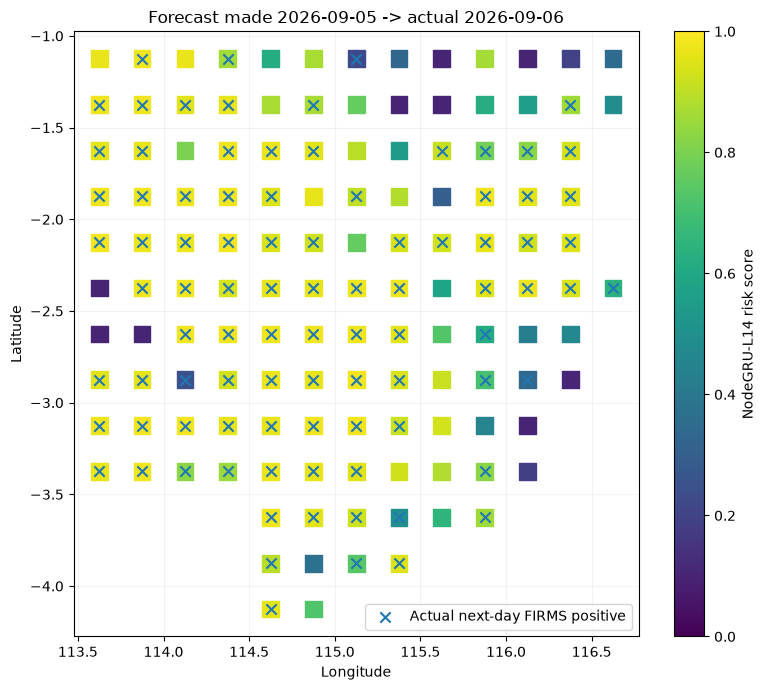

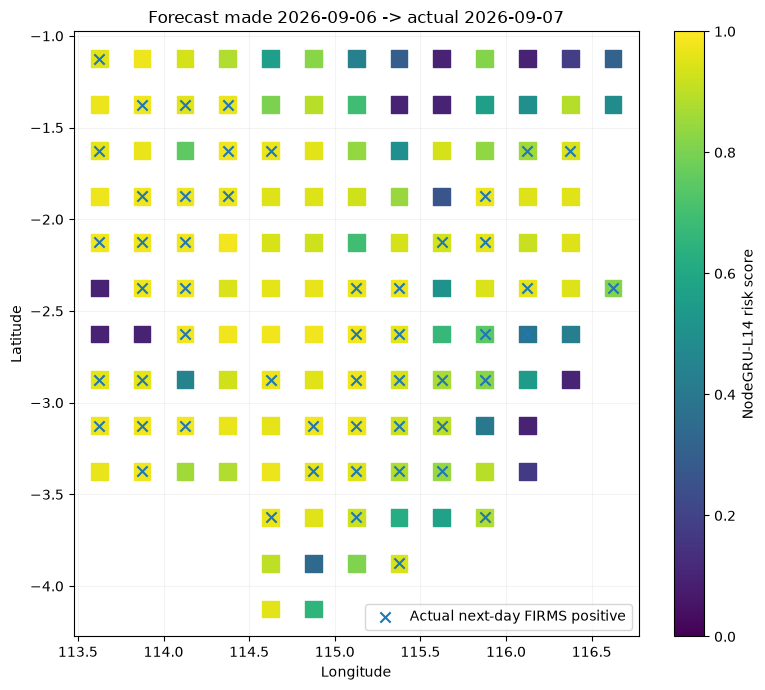

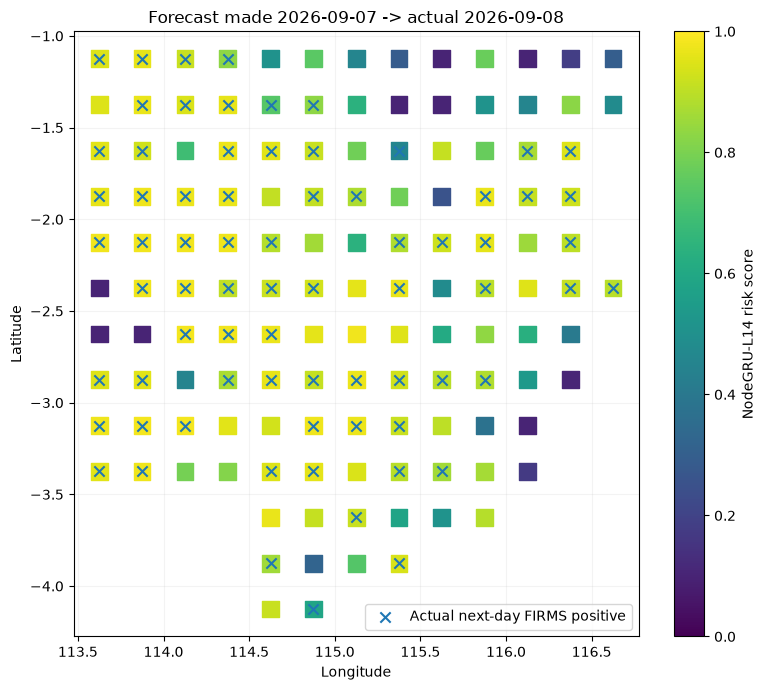

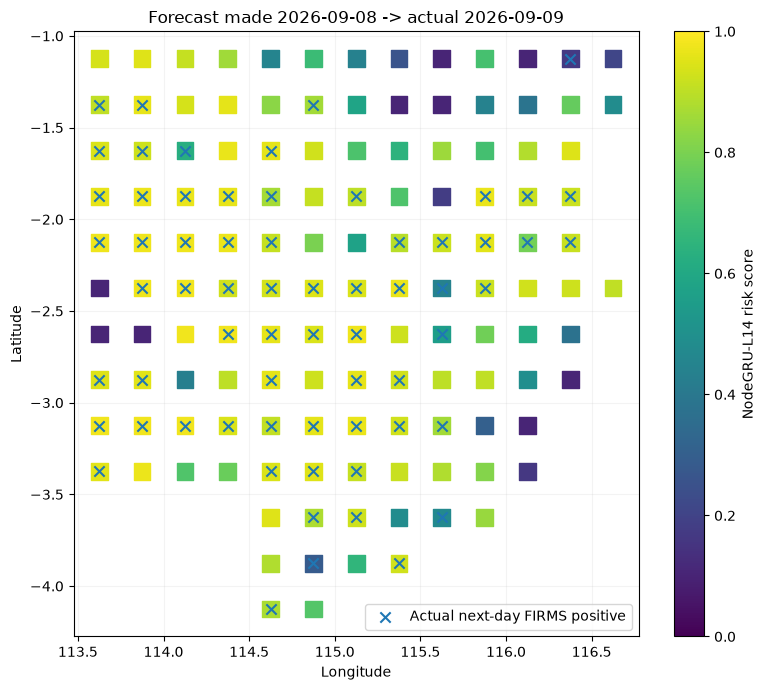

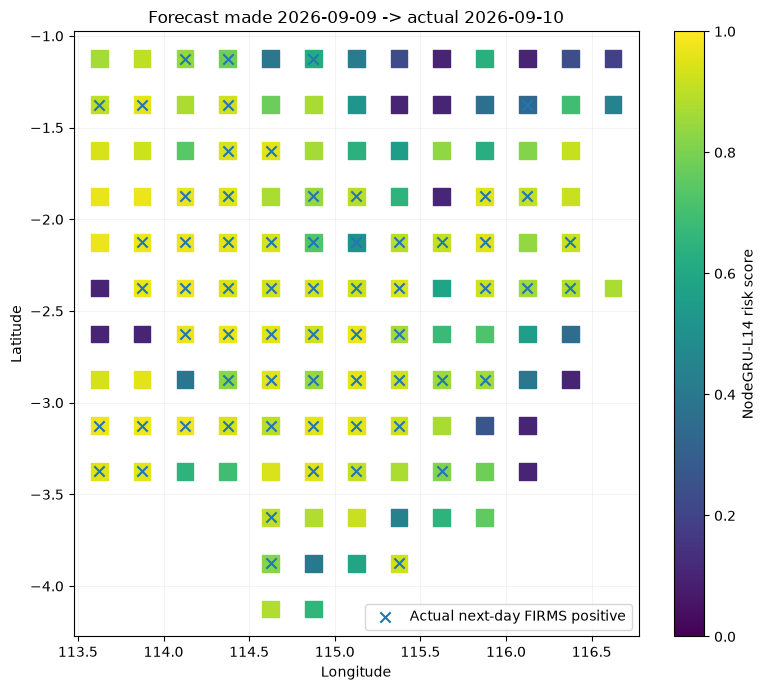

Saved 9 daily maps to: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\figures\daily_maps


In [19]:
# 18. Generate one actual-vs-predicted risk map per forecast day

map_paths = []

for forecast_date, day in final_predictions.groupby("forecast_date"):
    fig, ax = plt.subplots(figsize=(8, 7))

    sc = ax.scatter(
        day["grid_lon"],
        day["grid_lat"],
        c=day["nodegru_l14_score"],
        marker="s",
        s=145,
        vmin=0,
        vmax=1,
    )

    actual = day[day["y_true"].eq(1)]

    ax.scatter(
        actual["grid_lon"],
        actual["grid_lat"],
        marker="x",
        s=55,
        linewidths=1.5,
        label="Actual next-day FIRMS positive",
    )

    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label("NodeGRU-L14 risk score")

    origin = pd.Timestamp(day["origin_date"].iloc[0])

    ax.set_title(
        f"Forecast made {origin.date()} -> actual {pd.Timestamp(forecast_date).date()}"
    )
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.15)
    ax.legend(loc="best")

    plt.tight_layout()

    path = MAPS_DIR / f"nodegru_actual_vs_pred_{pd.Timestamp(forecast_date).date()}.png"
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()

    map_paths.append(path)

print("Saved", len(map_paths), "daily maps to:", MAPS_DIR)

In [20]:
# 19. Top-10 predicted risk cells for each forecast day

top10 = (
    final_predictions
    .sort_values(
        ["forecast_date", "nodegru_l14_score"],
        ascending=[True, False],
    )
    .groupby("forecast_date", as_index=False)
    .head(10)
    [
        [
            "origin_date",
            "forecast_date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "nodegru_l14_score",
            "lr13_score",
            "y_true",
            "is_emerging_eligible",
        ]
    ]
)

display(top10)

,origin_date,forecast_date,cell_id,grid_lat,grid_lon,nodegru_l14_score,lr13_score,y_true,is_emerging_eligible
124,2026-09-01,2026-09-02,regional025_9_25,-2.125,114.375,0.981261,1.000000,1,False
98,2026-09-01,2026-09-02,regional025_7_24,-2.625,114.125,0.980456,1.000000,1,False
100,2026-09-01,2026-09-02,regional025_7_26,-2.625,114.625,0.980417,1.000000,1,False
110,2026-09-01,2026-09-02,regional025_8_24,-2.375,114.125,0.980400,1.000000,1,False
75,2026-09-01,2026-09-02,regional025_5_24,-3.125,114.125,0.980366,1.000000,1,False
...,...,...,...,...,...,...,...,...,...
1186,2026-09-09,2026-09-10,regional025_9_23,-2.125,113.875,0.975396,1.000000,1,False
1173,2026-09-09,2026-09-10,regional025_8_23,-2.375,113.875,0.973350,1.000000,1,False
1065,2026-09-09,2026-09-10,regional025_10_23,-1.875,113.875,0.972512,1.000000,0,False
1162,2026-09-09,2026-09-10,regional025_7_24,-2.625,114.125,0.970796,1.000000,1,False


# PART E — Emerging-event case study

This table asks the thesis-relevant question:

> For final-test cells that were positive at `t+1` after no local detection over `t-2:t`,
> how highly did the frozen model rank them **before** the target day?

Because September contains only a small number of days, always report the number of Emerging
positives together with PR-AUC; do not overinterpret a subgroup with very small `N`.

In [21]:
# 20. Emerging-positive event ranking analysis

case_rows = []

for forecast_date, day in final_predictions.groupby("forecast_date"):
    eligible = day[day["is_emerging_eligible"]].copy()

    if eligible.empty:
        continue

    eligible["gru_rank_among_emerging"] = (
        eligible["nodegru_l14_score"]
        .rank(method="min", ascending=False)
        .astype(int)
    )

    eligible["lr_rank_among_emerging"] = (
        eligible["lr13_score"]
        .rank(method="min", ascending=False)
        .astype(int)
    )

    n = len(eligible)

    eligible["gru_rank_percentile"] = (
        1.0
        - (eligible["gru_rank_among_emerging"] - 1) / max(n - 1, 1)
    )

    positives = eligible[eligible["y_true"].eq(1)]

    for _, row in positives.iterrows():
        case_rows.append({
            "origin_date": row["origin_date"],
            "forecast_date": row["forecast_date"],
            "cell_id": row["cell_id"],
            "grid_lat": row["grid_lat"],
            "grid_lon": row["grid_lon"],
            "NodeGRU score": row["nodegru_l14_score"],
            "LR13 score": row["lr13_score"],
            "GRU rank among Emerging-eligible": row["gru_rank_among_emerging"],
            "LR rank among Emerging-eligible": row["lr_rank_among_emerging"],
            "GRU rank percentile": row["gru_rank_percentile"],
            "GRU flagged at frozen threshold": row["nodegru_l14_flag"],
            "LR flagged at frozen threshold": row["lr13_flag"],
        })

emerging_cases = pd.DataFrame(case_rows)

print("Final-test Emerging positive events:", len(emerging_cases))

display(emerging_cases)

Final-test Emerging positive events: 28


,origin_date,forecast_date,cell_id,grid_lat,grid_lon,NodeGRU score,LR13 score,GRU rank among Emerging-eligible,LR rank among Emerging-eligible,GRU rank percentile,GRU flagged at frozen threshold,LR flagged at frozen threshold
0,2026-09-01,2026-09-02,regional025_10_29,-1.875,115.375,0.442715,0.240537,11,13,0.615385,False,False
1,2026-09-01,2026-09-02,regional025_12_31,-1.375,115.875,0.729012,0.672980,3,2,0.923077,False,False
2,2026-09-01,2026-09-02,regional025_12_34,-1.375,116.625,0.119346,0.209749,19,18,0.307692,False,False
3,2026-09-01,2026-09-02,regional025_2_28,-3.875,115.125,0.892888,0.797532,1,1,1.000000,True,True
4,2026-09-01,2026-09-02,regional025_7_33,-2.625,116.375,0.520123,0.224186,8,17,0.730769,False,False
5,2026-09-02,2026-09-03,regional025_9_28,-2.125,115.125,0.666247,0.310509,3,4,0.909091,False,False
6,2026-09-03,2026-09-04,regional025_7_32,-2.625,116.125,0.342789,0.240032,9,6,0.619048,False,False
7,2026-09-04,2026-09-05,regional025_1_27,-4.125,114.875,0.632864,0.272256,4,8,0.880000,False,False
8,2026-09-04,2026-09-05,regional025_4_31,-3.375,115.875,0.757156,0.423288,1,2,1.000000,False,False
9,2026-09-05,2026-09-06,regional025_13_28,-1.125,115.125,0.221322,0.223477,19,13,0.379310,False,False


In [22]:
# 21. Runtime summary

display(runtime_final)

print(
    "Mean rolling NodeGRU ensemble training seconds per forecast origin:",
    round(runtime_final["NodeGRU ensemble fit seconds"].mean(), 3),
)

,origin_date,forecast_date,NodeGRU ensemble fit seconds,Mean per-seed seconds
0,2026-09-01,2026-09-02,29.078981,9.692994
1,2026-09-02,2026-09-03,28.756852,9.585617
2,2026-09-03,2026-09-04,29.402851,9.800950
3,2026-09-04,2026-09-05,29.631355,9.877118
4,2026-09-05,2026-09-06,29.947315,9.982438
5,2026-09-06,2026-09-07,29.860918,9.953639
6,2026-09-07,2026-09-08,29.999978,9.999993
7,2026-09-08,2026-09-09,30.400100,10.133367
8,2026-09-09,2026-09-10,30.635965,10.211988


Mean rolling NodeGRU ensemble training seconds per forecast origin: 29.746


# PART F — Export final thesis artifacts

In [23]:
# 22. Export final tables

paths = {
    "predictions": EXPORT_DIR / "final_september_predictions.csv",
    "overall": EXPORT_DIR / "final_overall_metrics.csv",
    "subgroups": EXPORT_DIR / "final_subgroup_metrics.csv",
    "deltas": EXPORT_DIR / "final_model_deltas.csv",
    "daily": EXPORT_DIR / "final_daily_metrics.csv",
    "top10": EXPORT_DIR / "final_top10_daily_risk.csv",
    "emerging_cases": EXPORT_DIR / "final_emerging_cases.csv",
    "runtime": EXPORT_DIR / "final_runtime.csv",
}

final_predictions.to_csv(paths["predictions"], index=False)
final_overall.to_csv(paths["overall"], index=False)
final_subgroups.to_csv(paths["subgroups"], index=False)
final_deltas.to_csv(paths["deltas"], index=False)
daily_metrics.to_csv(paths["daily"], index=False)
top10.to_csv(paths["top10"], index=False)
emerging_cases.to_csv(paths["emerging_cases"], index=False)
runtime_final.to_csv(paths["runtime"], index=False)

print("Saved final artifacts:")
for p in paths.values():
    print("-", p)

Saved final artifacts:
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\exports\final_september_predictions.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\exports\final_overall_metrics.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\exports\final_subgroup_metrics.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\exports\final_model_deltas.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\exports\final_daily_metrics.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\exports\final_top10_daily_risk.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\exports\final_emerging_cases.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_final_test\t2\exports\final_runtime.csv


In [24]:
# 23. Final automatic summary for thesis review

print("=== Notebook 21 — FINAL SEPTEMBER ROLLING BACKTEST ===")
print()
print("METHOD LOCK")
print("Main model       : NodeGRU-L14 ensemble")
print("Benchmark        : LR13")
print("Sequence length  :", SEQ_LEN)
print("Seeds            :", SEEDS)
print("Epochs           :", FROZEN_EPOCHS)
print("Forecast origins :", TEST_START.date(), "->", TEST_END.date())
print("Forecast targets :", (TEST_START + pd.Timedelta(days=1)).date(), "->", (TEST_END + pd.Timedelta(days=1)).date())
print("Evaluation       : rolling origin, no t+1 leakage")
print()

print("FINAL OVERALL")
display(final_overall)

print("FINAL SUBGROUPS")
display(final_subgroups)

print("FINAL DELTA")
display(final_deltas)

print("DAILY METRICS")
display(
    daily_metrics[
        [
            "forecast_date",
            "Model",
            "Positives",
            "PR-AUC",
            "Precision",
            "Recall",
            "F1",
        ]
    ]
)

print("EMERGING POSITIVE CASES")
display(emerging_cases)

print()
print("INTERPRETATION GUARDRAILS")
print("- PR-AUC is not accuracy.")
print("- Raw scores are risk scores, not calibrated probabilities.")
print("- FIRMS zero means no observed detection, not confirmed absence of fire.")
print("- Emerging means next-day positive after no local detection over t-2:t; it is not proof of ignition.")
print("- Do not change the selected architecture after seeing these final-test results.")

=== Notebook 21 — FINAL SEPTEMBER ROLLING BACKTEST ===

METHOD LOCK
Main model       : NodeGRU-L14 ensemble
Benchmark        : LR13
Sequence length  : 14
Seeds            : [42, 52, 62]
Epochs           : {42: 18, 52: 22, 62: 21}
Forecast origins : 2026-09-01 -> 2026-09-09
Forecast targets : 2026-09-02 -> 2026-09-10
Evaluation       : rolling origin, no t+1 leakage

FINAL OVERALL


,Model,Rows,Positives,Prevalence,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier,Threshold
0,LR13,1197,684,0.571429,0.888116,0.863457,0.788904,0.852339,0.819396,0.785297,0.187359,0.784092
1,NodeGRU-L14 ensemble,1197,684,0.571429,0.882435,0.865785,0.764563,0.921053,0.835544,0.792815,0.213023,0.823995


FINAL SUBGROUPS


,Model,Context,Rows,Positives,Prevalence,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier,Threshold
0,LR13,Emerging-3 eligible,252,28,0.111111,0.289877,0.709104,1.000000,0.071429,0.133333,0.896825,0.111191,0.784092
1,LR13,Persistent-context,945,656,0.694180,0.897755,0.798609,0.788331,0.885671,0.834171,0.755556,0.207670,0.784092
2,NodeGRU-L14 ensemble,Emerging-3 eligible,252,28,0.111111,0.326900,0.742506,0.750000,0.107143,0.187500,0.896825,0.169909,0.823995
3,NodeGRU-L14 ensemble,Persistent-context,945,656,0.694180,0.891270,0.800337,0.764634,0.955793,0.849593,0.765079,0.224520,0.823995


FINAL DELTA


,Comparison,Delta overall PR-AUC,Delta Emerging PR-AUC,Delta Persistent PR-AUC
0,NodeGRU-L14 - LR13,-0.005681,0.037022,-0.006485


DAILY METRICS


,forecast_date,Model,Positives,PR-AUC,Precision,Recall,F1
0,2026-09-02,LR13,84,0.946325,0.808511,0.904762,0.853933
1,2026-09-02,NodeGRU-L14 ensemble,84,0.945209,0.822917,0.940476,0.877778
2,2026-09-03,LR13,91,0.963455,0.919540,0.879121,0.898876
3,2026-09-03,NodeGRU-L14 ensemble,91,0.959028,0.875000,0.923077,0.898396
4,2026-09-04,LR13,84,0.958127,0.857143,0.928571,0.891429
5,2026-09-04,NodeGRU-L14 ensemble,84,0.955441,0.821053,0.928571,0.871508
6,2026-09-05,LR13,81,0.885124,0.818182,0.888889,0.852071
7,2026-09-05,NodeGRU-L14 ensemble,81,0.901853,0.797872,0.925926,0.857143
8,2026-09-06,LR13,91,0.941316,0.875000,0.846154,0.860335
9,2026-09-06,NodeGRU-L14 ensemble,91,0.944720,0.872340,0.901099,0.886486


EMERGING POSITIVE CASES


,origin_date,forecast_date,cell_id,grid_lat,grid_lon,NodeGRU score,LR13 score,GRU rank among Emerging-eligible,LR rank among Emerging-eligible,GRU rank percentile,GRU flagged at frozen threshold,LR flagged at frozen threshold
0,2026-09-01,2026-09-02,regional025_10_29,-1.875,115.375,0.442715,0.240537,11,13,0.615385,False,False
1,2026-09-01,2026-09-02,regional025_12_31,-1.375,115.875,0.729012,0.672980,3,2,0.923077,False,False
2,2026-09-01,2026-09-02,regional025_12_34,-1.375,116.625,0.119346,0.209749,19,18,0.307692,False,False
3,2026-09-01,2026-09-02,regional025_2_28,-3.875,115.125,0.892888,0.797532,1,1,1.000000,True,True
4,2026-09-01,2026-09-02,regional025_7_33,-2.625,116.375,0.520123,0.224186,8,17,0.730769,False,False
5,2026-09-02,2026-09-03,regional025_9_28,-2.125,115.125,0.666247,0.310509,3,4,0.909091,False,False
6,2026-09-03,2026-09-04,regional025_7_32,-2.625,116.125,0.342789,0.240032,9,6,0.619048,False,False
7,2026-09-04,2026-09-05,regional025_1_27,-4.125,114.875,0.632864,0.272256,4,8,0.880000,False,False
8,2026-09-04,2026-09-05,regional025_4_31,-3.375,115.875,0.757156,0.423288,1,2,1.000000,False,False
9,2026-09-05,2026-09-06,regional025_13_28,-1.125,115.125,0.221322,0.223477,19,13,0.379310,False,False



INTERPRETATION GUARDRAILS
- PR-AUC is not accuracy.
- Raw scores are risk scores, not calibrated probabilities.
- FIRMS zero means no observed detection, not confirmed absence of fire.
- Emerging means next-day positive after no local detection over t-2:t; it is not proof of ignition.
- Do not change the selected architecture after seeing these final-test results.


# What to send for review

After **Run All**, send the executed NB21 notebook, or at minimum:

1. Section 13 — final overall metrics;
2. Section 14 — final Emerging/Persistent metrics;
3. Section 15 — final deltas;
4. Section 16 — daily metrics;
5. Section 20 — Emerging-positive cases;
6. Section 23 — final automatic summary.

Also keep the generated maps under:

```text
model_results/regional_025_final_test/t2/figures/daily_maps/
```

After NB21, the held-out test has been consumed. Any later model redesign must be described as
post-test exploratory work rather than a new untouched final test.